Step 0: Load the Dataset

I will load the diabetes_prediction_dataset using Pandas. 
I will check its structure to understand the available columns and rows.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes_prediction_dataset.csv")

In [2]:
print(df.shape)

(100000, 9)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [4]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [5]:
print(df.columns)

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')


In [6]:
print(df.describe())

                 age  hypertension  heart_disease            bmi  \
count  100000.000000  100000.00000  100000.000000  100000.000000   
mean       41.885856       0.07485       0.039420      27.320767   
std        22.516840       0.26315       0.194593       6.636783   
min         0.080000       0.00000       0.000000      10.010000   
25%        24.000000       0.00000       0.000000      23.630000   
50%        43.000000       0.00000       0.000000      27.320000   
75%        60.000000       0.00000       0.000000      29.580000   
max        80.000000       1.00000       1.000000      95.690000   

         HbA1c_level  blood_glucose_level       diabetes  
count  100000.000000        100000.000000  100000.000000  
mean        5.527507           138.058060       0.085000  
std         1.070672            40.708136       0.278883  
min         3.500000            80.000000       0.000000  
25%         4.800000           100.000000       0.000000  
50%         5.800000           14

In [7]:
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


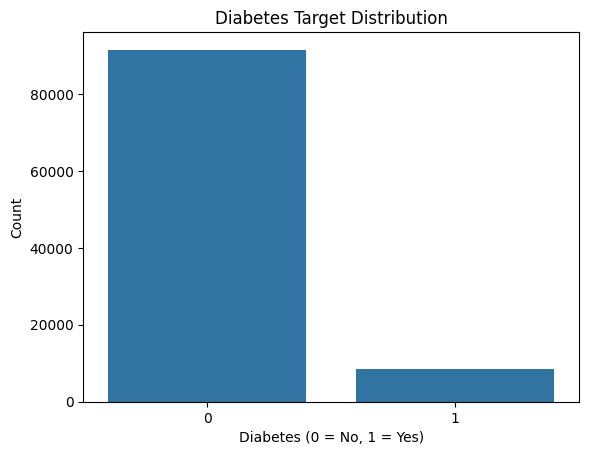

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="diabetes")
plt.title("Diabetes Target Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

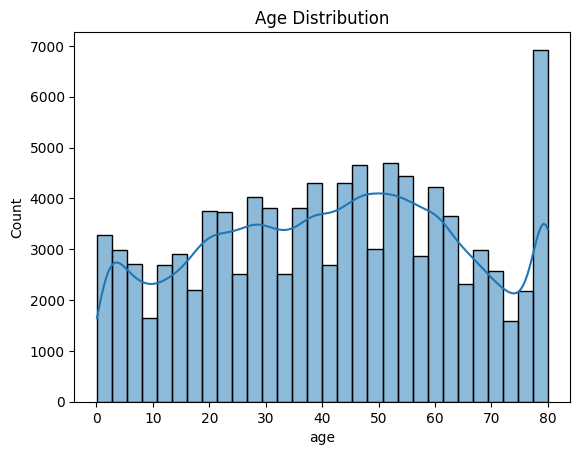

In [9]:
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Age Distribution")
plt.show()


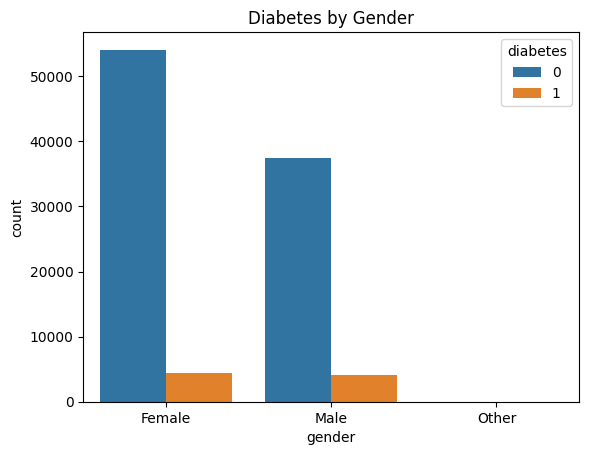

In [10]:
sns.countplot(data=df, x="gender", hue="diabetes")
plt.title("Diabetes by Gender")
plt.show()

I removed the duplicate rows. The column smoking_history has the text “No Info” for about 34% of the rows, which is a hidden missing value, so I converted it to NaN. I decided to fill it with the most frequent value (in Step 6, using train data only) because dropping the rows would lose a third of the data, and dropping the column would lose a useful feature. There is no ID or name column, so I did not drop any column.

Duplicates: 3854
gender                     0
age                        0
hypertension               0
heart_disease              0
smoking_history        32887
bmi                        0
HbA1c_level                0
blood_glucose_level        0
diabetes                   0
dtype: int64


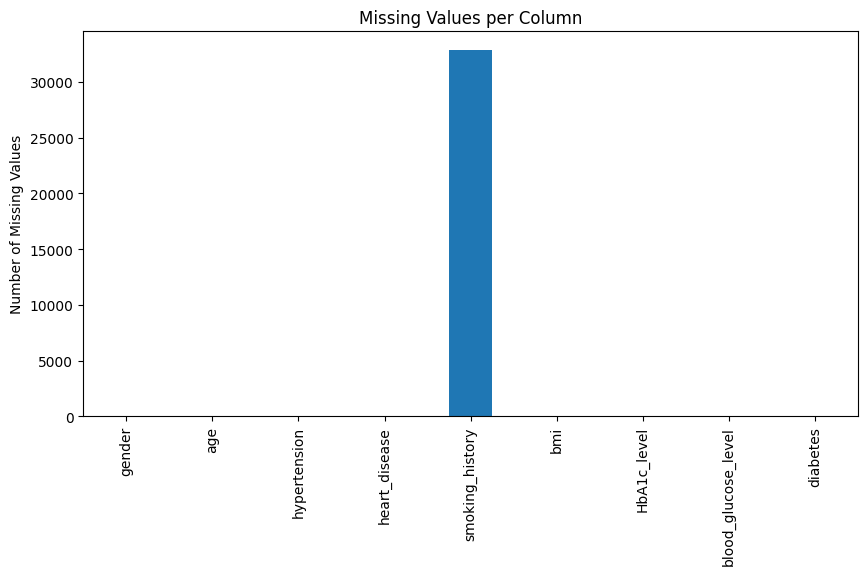

Shape after cleaning: (96146, 9)


In [11]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df["smoking_history"] = df["smoking_history"].replace("No Info", np.nan)

print(df.isnull().sum())
df.isnull().sum().plot(kind="bar", figsize=(10, 5))
plt.title("Missing Values per Column")
plt.ylabel("Number of Missing Values")
plt.show()
print("Shape after cleaning:", df.shape)

Correlation heatmap of the cleaned data.

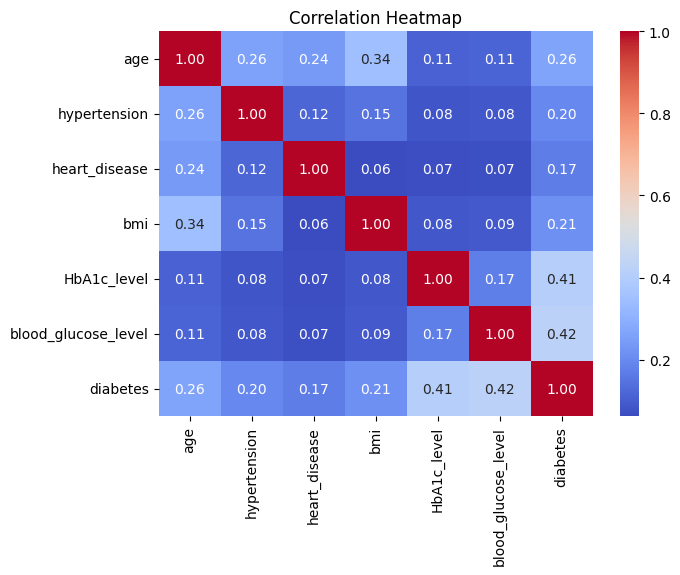

In [12]:
plt.figure(figsize=(7,5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

Step 3: Feature Engineering

I created two new features: age_group and bmi_category. 
The age_group feature groups people by age, 
while bmi_category classifies people according to their BMI. 
These features may help the model identify patterns related to diabetes prediction.

In [13]:
# Feature 1: Age group
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 18, 35, 50, 65, 100],
    labels=["Teen", "Young Adult", "Adult", "Middle Age", "Senior"]
)

# Feature 2: BMI category
df["bmi_category"] = pd.cut(
    df["bmi"],
    bins=[0, 18.5, 25, 30, float("inf")],
    labels=["Underweight", "Normal", "Overweight", "Obese"],
    right=False
)

df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,age_group,bmi_category
0,Female,80.0,0,1,never,25.19,6.6,140,0,Senior,Overweight
1,Female,54.0,0,0,NaN,27.32,6.6,80,0,Middle Age,Overweight
2,Male,28.0,0,0,never,27.32,5.7,158,0,Young Adult,Overweight
3,Female,36.0,0,0,current,23.45,5.0,155,0,Adult,Normal
4,Male,76.0,1,1,current,20.14,4.8,155,0,Senior,Normal


Step 4: Select features and target

y is the target column diabetes (what I want to predict). X is all other columns, including the two new features.

In [14]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

print("X shape:", X.shape)


X shape: (96146, 10)


Step 5: Train/Test Split

I split the dataset into 80% training data and 20% testing data. 
I used random_state=42 to make the split reproducible and stratify=y to maintain the diabetes class proportions in both sets.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))

X_train: (76916, 10)
X_test: (19230, 10)
y_train: (76916,)
y_test: (19230,)

Training class proportions:
diabetes
0    0.911774
1    0.088226
Name: proportion, dtype: float64

Testing class proportions:
diabetes
0    0.911804
1    0.088196
Name: proportion, dtype: float64


Step 6: Data Preprocessing

I will preprocess numerical and categorical features separately using a ColumnTransformer. 
Numerical features will be imputed with the median and scaled using StandardScaler. 
Categorical features will be imputed with the most frequent value and encoded using OneHotEncoder. 
I will fit the preprocessing pipeline only on the training data to avoid data leakage.

In [16]:
numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

categorical_features = [
    "gender",
    "smoking_history",
    "age_group",
    "bmi_category"
]

In [17]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [18]:
# Split 
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = preprocessor.fit_transform(X_train_raw)
X_test  = preprocessor.transform(X_test_raw)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (76916, 23)
Testing shape: (19230, 23)


Step 7: Final Checks

I will verify the final dimensions of the processed training and testing data. 
I will also check for missing values and confirm that the test data was only transformed, not used to fit the preprocessing pipeline.

In [19]:
from scipy import sparse
import numpy as np

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Check missing values in processed features
if sparse.issparse(X_train):
    train_missing = np.isnan(X_train.data).sum()
    test_missing = np.isnan(X_test.data).sum()
else:
    train_missing = np.isnan(X_train).sum()
    test_missing = np.isnan(X_test).sum()

print("Missing values in X_train:", train_missing)
print("Missing values in X_test:", test_missing)

print("Missing values in y_train:", y_train.isna().sum())
print("Missing values in y_test:", y_test.isna().sum())
scaler = preprocessor.named_transformers_["num"]["scaler"]
print("From how much rows Scaler learned :", scaler.n_samples_seen_, "| train rows:", len(X_train_raw))
print("Scaler mean == TRAIN mean:", np.allclose(scaler.mean_, X_train_raw[numeric_features].mean().values))
print("Scaler mean == TEST mean :", np.allclose(scaler.mean_, X_test_raw[numeric_features].mean().values))

X_train shape: (76916, 23)
X_test shape: (19230, 23)
y_train shape: (76916,)
y_test shape: (19230,)
Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0
From how much rows Scaler learned : 76916 | train rows: 76916
Scaler mean == TRAIN mean: True
Scaler mean == TEST mean : False
